# Introduction

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt
import numpy as np
import copy
import os

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")



Using device: cpu


## Permuted preprocessing

In [2]:
# Path to existing MNIST data (update this path if needed)
MNIST_DATA_PATH = '/Users/yann/Documents/inference-NN-forgor-project/tested_codes/pytorch-ewc/datasets/mnist'

In [3]:
def get_permuted_mnist_tasks(num_tasks=3, batch_size=128):
    """Generates Permuted MNIST tasks."""
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,)),
        transforms.Lambda(lambda x: x.view(-1))
    ])

    # Load data once - using existing MNIST data - set download to True if no MNIST pre-dowloaded
    train_dataset = datasets.MNIST(root=MNIST_DATA_PATH, train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root=MNIST_DATA_PATH, train=False, download=True, transform=transform)

    # Pre-load to CPU tensors
    x_train_base = train_dataset.data.float() / 255.0
    x_train_base = (x_train_base - 0.1307) / 0.3081
    x_train_base = x_train_base.view(-1, 784)
    y_train_base = train_dataset.targets

    x_test_base = test_dataset.data.float() / 255.0
    x_test_base = (x_test_base - 0.1307) / 0.3081
    x_test_base = x_test_base.view(-1, 784)
    y_test_base = test_dataset.targets

    tasks = []

    for i in range(num_tasks):
        if i == 0:
            perm = torch.arange(784) # Task 1 is standard MNIST
        else:
            perm = torch.randperm(784) # Others are permuted

        # Apply permutation
        x_train_perm = x_train_base[:, perm]
        x_test_perm = x_test_base[:, perm]

        train_ds = TensorDataset(x_train_perm, y_train_base)
        test_ds = TensorDataset(x_test_perm, y_test_base)

        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
        test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

        tasks.append((train_loader, test_loader))

    return tasks

## Model and Fisher

In [4]:
class MLP(nn.Module):
    def __init__(self, input_size=784, hidden_size=400, output_size=10):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

def fisher_matrix_diag(model, train_loader, device, num_samples=500):
    """
    Computes the diagonal Fisher Matrix using a subset of the data.
    """
    model.eval()
    fisher = {n: torch.zeros_like(p) for n, p in model.named_parameters()}

    # Create a cleaner loader with batch_size=1 for correct Fisher calculation
    # (The diagonal Fisher is the expectation of the squared gradients)
    fisher_loader = DataLoader(train_loader.dataset, batch_size=1, shuffle=True)

    count = 0
    for data, target in fisher_loader:
        if count >= num_samples:
            break

        data, target = data.to(device), target.to(device)
        model.zero_grad()
        output = model(data)

        # Standard EWC uses the negative log-likelihood (CrossEntropy)
        loss = F.cross_entropy(output, target)
        loss.backward()

        for n, p in model.named_parameters():
            if p.grad is not None:
                # F_i = E[ (dL/dtheta)^2 ]
                fisher[n] += p.grad.data ** 2

        count += 1

    # Normalize
    for n in fisher:
        fisher[n] /= count

    return fisher

## Plotting functions

In [9]:
# --- Plotting ---
def plot_results(hist_ewc, hist_l2, hist_sgd, EPOCHS_PER_TASK = 5, num_tasks = 10):
    # Figure 2A recreation
    fig, axes = plt.subplots(3, 1, figsize=(7, 5), sharex=True)

    # Only plot up to end of train C (3 tasks)
    x_limit = 3 * EPOCHS_PER_TASK
    x_axis = np.arange(x_limit)
    show_n_tasks = 3
    plt.rcParams['font.size'] = 12

    
    for task_idx in range(show_n_tasks):
        ax = axes[task_idx]
        
        ax.plot(x_axis, hist_ewc[task_idx][:x_limit], color='red', linewidth=2)
        ax.plot(x_axis, hist_l2[task_idx][:x_limit], color='green', linewidth=2)
        ax.plot(x_axis, hist_sgd[task_idx][:x_limit], color='blue', linewidth=2)
        
        for i in range(show_n_tasks):
            x_pos = i * EPOCHS_PER_TASK
            ax.axvline(x=x_pos, color='gray', linestyle='--', alpha=0.5)
            if task_idx == 0:
                ax.text(x_pos + EPOCHS_PER_TASK/2, 1.01, f'train {chr(65+i)}', 
                    ha='center', va='bottom', fontsize=15)
        
        ax.set_ylim(0.8, 1.0)
        ax.set_yticks([0.8, 1.0])
        ax.set_ylabel(f'Task {chr(65+task_idx)}', rotation=0, labelpad=35, 
                    fontsize=15, va='center', ha='right')
        
        if task_idx == 0:
            ax.legend(['EWC', 'L2', 'SGD'], loc='right', frameon=False, 
                    bbox_to_anchor=(1.0, 0.5))
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        
        ax.set_xlim(0, x_limit)

    axes[2].set_xlabel('Training time', fontsize=15)

    fig.text(0.01, 0.5, 'Frac. correct', rotation=90, va='center', ha='center', fontsize=15)
    plt.tight_layout(rect=[0.02, 0, 1, 0.95])
    plt.subplots_adjust(hspace=0.1)
    plt.show()

    # Figure 2B recreation
    avg_acc_ewc = []
    avg_acc_l2 = []
    avg_acc_sgd = []

    # Calculate average accuracy at the end of each task block
    
    for t in range(num_tasks):
        # Index in history corresponding to end of task t
        end_idx = (t + 1) * EPOCHS_PER_TASK - 1
        e_accs = [hist_ewc[i][end_idx] for i in range(t+1)]
        l_accs = [hist_l2[i][end_idx] for i in range(t+1)]
        s_accs = [hist_sgd[i][end_idx] for i in range(t+1)]

        avg_acc_ewc.append(np.mean(e_accs))
        avg_acc_l2.append(np.mean(l_accs))
        avg_acc_sgd.append(np.mean(s_accs))

    plt.plot(range(1, num_tasks+1), avg_acc_ewc, 'o-', label='EWC', color='red', linewidth=2)
    plt.plot(range(1, num_tasks+1), avg_acc_l2, 'o-', label='L2', color='green', linewidth=2)
    plt.plot(range(1, num_tasks+1), avg_acc_sgd, 'o--', label='SGD', color='blue')
    plt.xlabel('Number of Tasks Trained')
    plt.ylabel('Average Accuracy (on trained tasks)')
    plt.ylim(0, 1.05)
    plt.xticks(range(1, num_tasks+1))
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    

    # Figure C: task 1 and 2 performance over training time

    plt.figure(figsize=(7, 5))
    x_axis = np.arange(len(hist_ewc[0]))
    # Vertical lines indicating task switches
    for i in range(1, num_tasks):
        plt.axvline(x=i*EPOCHS_PER_TASK, color='gray', linestyle='--', alpha=0.5)

    plt.plot(x_axis, hist_ewc[0], label='EWC (Task 1)', color='red', linewidth=2)
    plt.plot(x_axis, hist_l2[0], label='L2 (Task 1)', color='green', linewidth=2)
    plt.plot(x_axis, hist_sgd[0], label='SGD (Task 1)', color='blue', linestyle='--')
    plt.plot(x_axis, hist_ewc[1], label='EWC (Task 2)', color='red', alpha=0.5) # Show Task 2 too
    plt.plot(x_axis, hist_l2[1], label='L2 (Task 2)', color='green', alpha=0.5)
    plt.plot(x_axis, hist_sgd[1], label='SGD (Task 2)', color='blue', linestyle=':', alpha=0.5)
    plt.xlabel('Training Epochs')
    plt.ylabel('Test Accuracy')
    plt.ylim(0, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()



# Comprehensive Experiments: PermutedMNIST and RotatedMNIST

This section reproduces Figure 2 (subfigures A + B) from the paper, comparing:
- EWC (proposed regularization)
- L2 regularization  
- No regularization (SGD baseline)

On both PermutedMNIST and RotatedMNIST datasets.

## Figure 2A and 2B: PermutedMNIST Results

### EWC class and training loop

In [10]:
class EWC:
    def __init__(self, model: nn.Module, lambda_ewc: float = 2000):
        self.model = model
        self.lambda_ewc = lambda_ewc
        self.tasks = [] # Stores (params, fisher) tuples for each previous task

    def register_task(self, train_loader, device):
        """
        Called after finishing a task. Computes and stores the Fisher Matrix
        and current parameters.
        """
        params = {n: p.data.clone().cpu() for n, p in self.model.named_parameters()}
        fisher = fisher_matrix_diag(self.model, train_loader, device)
        # Move fisher to CPU to save GPU memory
        fisher = {n: f.cpu() for n, f in fisher.items()}
        self.tasks.append((params, fisher))
        print(f"Task registered. Total stored tasks: {len(self.tasks)}")

    def penalty(self, device):
        """
        Calculates the EWC loss penalty by summing over all previous tasks.
        """
        loss = 0
        for params_old, fisher_old in self.tasks:
            for n, p in self.model.named_parameters():
                # Move stored tensors to device for calculation
                f = fisher_old[n].to(device)
                p_old = params_old[n].to(device)

                # Loss = sum( F * (current - old)^2 )
                loss += (f * (p - p_old) ** 2).sum()

        # return (self.lambda_ewc / 2) * loss # original un-normalized loss
        return (self.lambda_ewc / (2 * max(1, len(self.tasks)))) * loss # normalized by number of tasks
        

def train_and_evaluate(model, tasks, device, method='ewc', epochs=5, lambda_ewc=2000, lambda_l2=0.0, lr=0.1):
    """
    Trains on tasks sequentially and records accuracy on ALL tasks at every epoch
    to facilitate Figure 2A reproduction.
    """
    model.to(device)
    optimizer = optim.SGD(model.parameters(), lr=lr)

    ewc = EWC(model, lambda_ewc)

    # Storage for plots
    # keys: task_index, values: list of accuracies over time
    history = {i: [] for i in range(len(tasks))}

    global_step = 0

    for task_id, (train_loader, _) in enumerate(tasks):
        print(f"\n--- Training on Task {task_id+1} ---")

        # Re-initialize optimizer for each task
        optimizer = optim.SGD(model.parameters(), lr=0.1)

        for epoch in range(epochs):
            model.train()
            for data, target in train_loader:
                data, target = data.to(device), target.to(device)
                optimizer.zero_grad()
                output = model(data)
                loss = F.cross_entropy(output, target)

                # Add EWC penalty if applicable
                if method == 'ewc' and task_id > 0:
                    loss += ewc.penalty(device)
                elif method == 'l2':
                    # Naive L2 regularization (weight decay to zero)
                    l2_loss = 0
                    for p in model.parameters():
                        l2_loss += (p ** 2).sum()
                    loss += lambda_l2 * l2_loss

                loss.backward()
                optimizer.step()

            # Evaluation Step (End of Epoch) 
            # Evaluate on ALL tasks 
            model.eval()
            with torch.no_grad():
                for t_idx, (_, test_loader) in enumerate(tasks):
                    correct = 0
                    total = 0
                    for data, target in test_loader:
                        data, target = data.to(device), target.to(device)
                        output = model(data)
                        pred = output.argmax(dim=1)
                        correct += (pred == target).sum().item()
                        total += target.size(0)
                    acc = correct / total
                    history[t_idx].append(acc)

            print(f"Epoch {epoch+1}/{epochs} | Task {task_id+1} Acc: {history[task_id][-1]:.4f}")

        # Post-task: Register Fisher for EWC
        if method == 'ewc':
            ewc.register_task(train_loader, device)
        elif method == 'l2':
            # For L2, we just register the params, Fisher is ignored
            # We use the EWC class helper just to store params
            ewc.register_task(train_loader, device)

    return history

### Running experiments and plotting

In [7]:
# Generate tasks
num_tasks=10
tasks = get_permuted_mnist_tasks(num_tasks) 

# Configuration
EPOCHS_PER_TASK = 5  # 5 epochs is sufficient for MNIST convergence
LAMBDA = 100   # Hyperparameter for EWC importance

# 1. Run EWC
print("Running EWC...")
model_ewc = MLP().to(device)
hist_ewc = train_and_evaluate(model_ewc, tasks, device, method='ewc', epochs=EPOCHS_PER_TASK, lambda_ewc=LAMBDA)

# 2. Run SGD (No penalty)
print("\nRunning SGD (Catastrophic Forgetting)...")
model_sgd = MLP().to(device)
hist_sgd = train_and_evaluate(model_sgd, tasks, device, method='sgd', epochs=EPOCHS_PER_TASK)

# 3. Run L2 Regularization
print("\nRunning L2 Regularization...")
model_l2 = MLP().to(device)

hist_l2 = train_and_evaluate(model_l2, tasks, device, method='l2', epochs=EPOCHS_PER_TASK, lambda_ewc=LAMBDA)


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.85MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 130kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.42MB/s]


Running EWC...

--- Training on Task 1 ---
Epoch 1/5 | Task 1 Acc: 0.9459
Epoch 2/5 | Task 1 Acc: 0.9590
Epoch 3/5 | Task 1 Acc: 0.9704
Epoch 4/5 | Task 1 Acc: 0.9757
Epoch 5/5 | Task 1 Acc: 0.9768
Task registered. Total stored tasks: 1

--- Training on Task 2 ---
Epoch 1/5 | Task 2 Acc: 0.9630
Epoch 2/5 | Task 2 Acc: 0.9726
Epoch 3/5 | Task 2 Acc: 0.9711
Epoch 4/5 | Task 2 Acc: 0.9758
Epoch 5/5 | Task 2 Acc: 0.9765
Task registered. Total stored tasks: 2

--- Training on Task 3 ---
Epoch 1/5 | Task 3 Acc: 0.9565
Epoch 2/5 | Task 3 Acc: 0.9676
Epoch 3/5 | Task 3 Acc: 0.9693
Epoch 4/5 | Task 3 Acc: 0.9729
Epoch 5/5 | Task 3 Acc: 0.9756
Task registered. Total stored tasks: 3

--- Training on Task 4 ---
Epoch 1/5 | Task 4 Acc: 0.9646
Epoch 2/5 | Task 4 Acc: 0.9719
Epoch 3/5 | Task 4 Acc: 0.9681
Epoch 4/5 | Task 4 Acc: 0.9735
Epoch 5/5 | Task 4 Acc: 0.9763
Task registered. Total stored tasks: 4

--- Training on Task 5 ---
Epoch 1/5 | Task 5 Acc: 0.9587
Epoch 2/5 | Task 5 Acc: 0.9698
Epoch 3

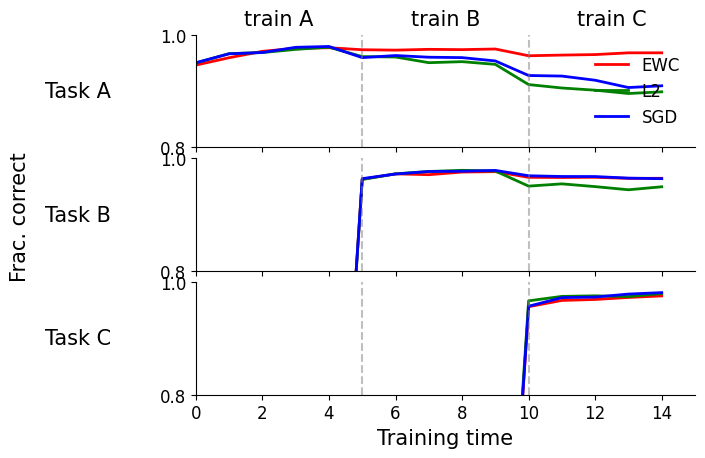

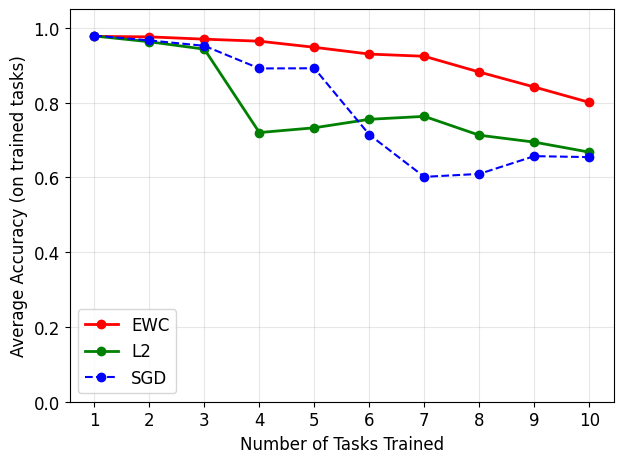

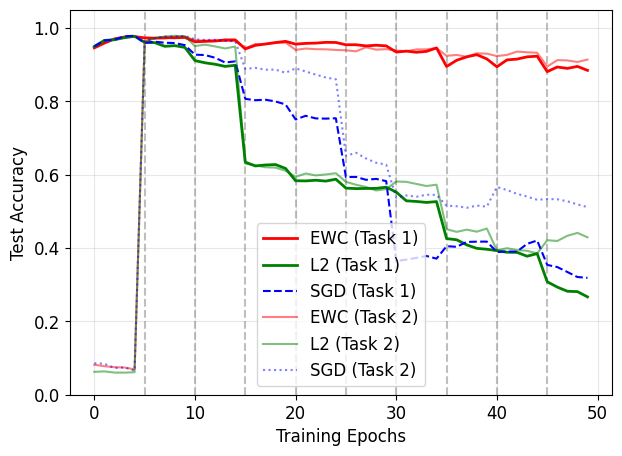

In [11]:
plot_results(hist_ewc, hist_l2, hist_sgd, EPOCHS_PER_TASK, num_tasks)

### Figure 2A and 2B: RotatedMNIST Results

In [13]:
def _load_full_mnist(train=True):
    loader = DataLoader(
        datasets.MNIST(root=MNIST_DATA_PATH, train=train, download=True, transform=transforms.ToTensor()),
        batch_size=60000 if train else 10000,
        shuffle=False
    )
    data, targets = next(iter(loader))
    return data, targets

def get_rotated_mnist_tasks(num_tasks=10, batch_size=128, angle_step=10):
    # Generates Rotated MNIST tasks with fixed rotations 
    tasks = []
    train_data, train_targets = _load_full_mnist(train=True)
    test_data, test_targets = _load_full_mnist(train=False)

    for i in range(num_tasks):
        angle = angle_step * i
        print(f"Generating Task {i+1} (Rotation {angle}°)...")

        X_train_rot = torch.stack([TF.rotate(img, angle) for img in train_data])
        X_test_rot = torch.stack([TF.rotate(img, angle) for img in test_data])

        # Normalize
        X_train_rot = (X_train_rot - 0.1307) / 0.3081
        X_test_rot = (X_test_rot - 0.1307) / 0.3081

        X_train_rot = X_train_rot.view(-1, 784)
        X_test_rot = X_test_rot.view(-1, 784)

        train_ds = TensorDataset(X_train_rot, train_targets)
        test_ds = TensorDataset(X_test_rot, test_targets)

        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
        test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

        tasks.append((train_loader, test_loader))

    return tasks

def train_and_evaluate_rotated(model, tasks, device, method="ewc", epochs=5, ewc_lambda=10, l2_lambda=10, lr=0.01):
    return train_and_evaluate(
        model,
        tasks,
        device,
        method=method,
        epochs=epochs,
        lambda_ewc=ewc_lambda,
        lambda_l2=l2_lambda,
        lr=lr,
    )


In [14]:
# Params
EWC_LAMBDA = 100
L2_LAMBDA = 1e-4
ROTATED_LR = 0.1
ROTATED_BATCH = 128
ROTATED_ANGLE_STEP = 10
EPOCHS_PER_TASK = 5  

# Generate rotated tasks (10 tasks, 0..90 degrees)
num_tasks=10
rotated_tasks = get_rotated_mnist_tasks(num_tasks=10, batch_size=ROTATED_BATCH, angle_step=ROTATED_ANGLE_STEP)


Generating Task 1 (Rotation 0°)...
Generating Task 2 (Rotation 10°)...
Generating Task 3 (Rotation 20°)...
Generating Task 4 (Rotation 30°)...
Generating Task 5 (Rotation 40°)...
Generating Task 6 (Rotation 50°)...
Generating Task 7 (Rotation 60°)...
Generating Task 8 (Rotation 70°)...
Generating Task 9 (Rotation 80°)...
Generating Task 10 (Rotation 90°)...


In [15]:
# Run EWC training
model_ewc_rot = MLP().to(device)
hist_ewc_rot = train_and_evaluate_rotated(model_ewc_rot, rotated_tasks, device, method="ewc", epochs=EPOCHS_PER_TASK, ewc_lambda=EWC_LAMBDA, l2_lambda=L2_LAMBDA, lr=ROTATED_LR)



--- Training on Task 1 ---
Epoch 1/5 | Task 1 Acc: 0.9474
Epoch 2/5 | Task 1 Acc: 0.9647
Epoch 3/5 | Task 1 Acc: 0.9695
Epoch 4/5 | Task 1 Acc: 0.9750
Epoch 5/5 | Task 1 Acc: 0.9749
Task registered. Total stored tasks: 1

--- Training on Task 2 ---
Epoch 1/5 | Task 2 Acc: 0.9710
Epoch 2/5 | Task 2 Acc: 0.9762
Epoch 3/5 | Task 2 Acc: 0.9741
Epoch 4/5 | Task 2 Acc: 0.9764
Epoch 5/5 | Task 2 Acc: 0.9765
Task registered. Total stored tasks: 2

--- Training on Task 3 ---
Epoch 1/5 | Task 3 Acc: 0.9720
Epoch 2/5 | Task 3 Acc: 0.9762
Epoch 3/5 | Task 3 Acc: 0.9714
Epoch 4/5 | Task 3 Acc: 0.9744
Epoch 5/5 | Task 3 Acc: 0.9715
Task registered. Total stored tasks: 3

--- Training on Task 4 ---
Epoch 1/5 | Task 4 Acc: 0.9734
Epoch 2/5 | Task 4 Acc: 0.9732
Epoch 3/5 | Task 4 Acc: 0.9754
Epoch 4/5 | Task 4 Acc: 0.9735
Epoch 5/5 | Task 4 Acc: 0.9744
Task registered. Total stored tasks: 4

--- Training on Task 5 ---
Epoch 1/5 | Task 5 Acc: 0.9711
Epoch 2/5 | Task 5 Acc: 0.9697
Epoch 3/5 | Task 5 Acc

In [16]:

# Run other training

print("\nRunning SGD (Catastrophic Forgetting) on RotatedMNIST...")
model_sgd_rot = MLP().to(device)
hist_sgd_rot = train_and_evaluate_rotated(model_sgd_rot, rotated_tasks, device, method="sgd", epochs=EPOCHS_PER_TASK, ewc_lambda=EWC_LAMBDA, l2_lambda=L2_LAMBDA, lr=ROTATED_LR)

print("\nRunning L2 Regularization on RotatedMNIST...")
model_l2_rot = MLP().to(device)
hist_l2_rot = train_and_evaluate_rotated(model_l2_rot, rotated_tasks, device, method="l2", epochs=EPOCHS_PER_TASK, ewc_lambda=EWC_LAMBDA, l2_lambda=L2_LAMBDA, lr=ROTATED_LR)



Running SGD (Catastrophic Forgetting) on RotatedMNIST...

--- Training on Task 1 ---
Epoch 1/5 | Task 1 Acc: 0.9494
Epoch 2/5 | Task 1 Acc: 0.9642
Epoch 3/5 | Task 1 Acc: 0.9700
Epoch 4/5 | Task 1 Acc: 0.9764
Epoch 5/5 | Task 1 Acc: 0.9765

--- Training on Task 2 ---
Epoch 1/5 | Task 2 Acc: 0.9756
Epoch 2/5 | Task 2 Acc: 0.9783
Epoch 3/5 | Task 2 Acc: 0.9814
Epoch 4/5 | Task 2 Acc: 0.9799
Epoch 5/5 | Task 2 Acc: 0.9822

--- Training on Task 3 ---
Epoch 1/5 | Task 3 Acc: 0.9775
Epoch 2/5 | Task 3 Acc: 0.9819
Epoch 3/5 | Task 3 Acc: 0.9810
Epoch 4/5 | Task 3 Acc: 0.9792
Epoch 5/5 | Task 3 Acc: 0.9819

--- Training on Task 4 ---
Epoch 1/5 | Task 4 Acc: 0.9784
Epoch 2/5 | Task 4 Acc: 0.9790
Epoch 3/5 | Task 4 Acc: 0.9758
Epoch 4/5 | Task 4 Acc: 0.9822
Epoch 5/5 | Task 4 Acc: 0.9812

--- Training on Task 5 ---
Epoch 1/5 | Task 5 Acc: 0.9767
Epoch 2/5 | Task 5 Acc: 0.9784
Epoch 3/5 | Task 5 Acc: 0.9824
Epoch 4/5 | Task 5 Acc: 0.9820
Epoch 5/5 | Task 5 Acc: 0.9838

--- Training on Task 6 ---

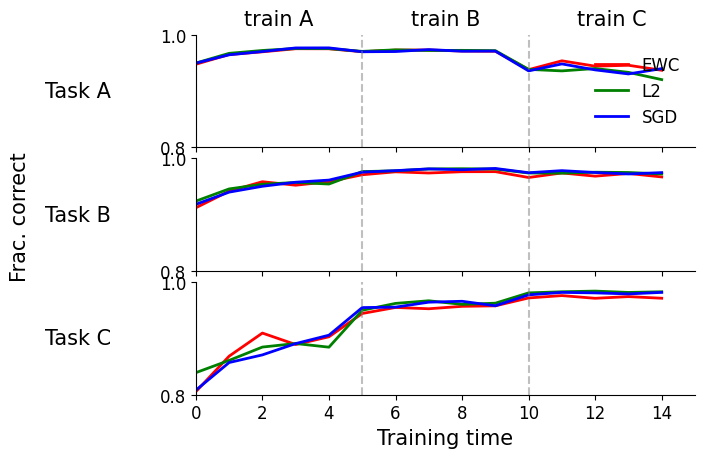

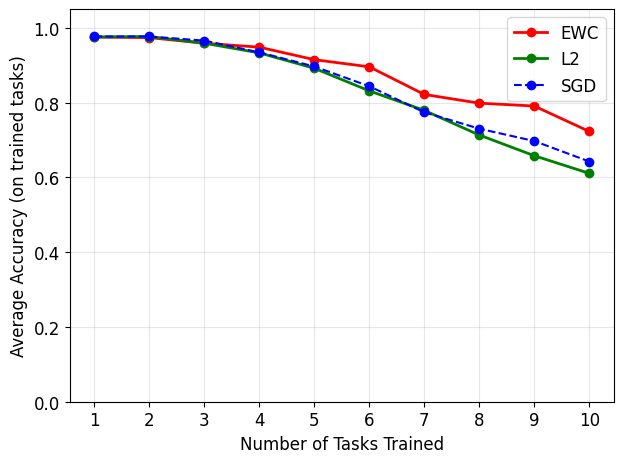

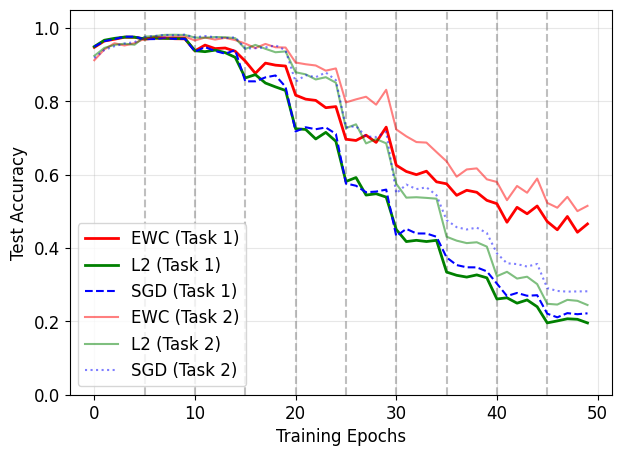

In [17]:
plot_results(hist_ewc_rot, hist_l2_rot, hist_sgd_rot, EPOCHS_PER_TASK, num_tasks)